In [341]:
import pandas as pd
import missingno as msno
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy.stats import zscore
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, RANSACRegressor
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import KNNImputer, IterativeImputer, SimpleImputer
from sklearn.preprocessing import OrdinalEncoder

In [342]:
train_df = pd.read_csv(r"C:\Users\gelet\PycharmProjects\stop-and-search\data\cleaned_data\stop_search_train1.csv", index_col=0)

In [343]:
train_df

,District,Zone,StopDescription,VehicleYear,VehicleStyle,VehicleColor,SubjectID,SubjectRace,SubjectGender,SubjectAge,...,month,year,weekend,isDriver,isLA,orig_height,orig_weight,BMI,vital_flag,orig_age
FieldInterviewID,,,,,,,,,,,,,,,,,,,,,
542115,3,D,SUSPECT VEHICLE,2014.0,FOUR DOOR,BLUE,621847,BLACK,0.0,22.0,...,8,2020,0,1,1.0,76.0,200.0,24.342105,0,22.0
667644,5,K,TRAFFIC VIOLATION,2007.0,SPORTS UTILITY,BLACK,761029,BLACK,0.0,57.0,...,4,2025,0,1,1.0,69.0,180.0,26.578450,0,57.0
617735,4,D,TRAFFIC VIOLATION,2022.0,SPORTS UTILITY,GRAY,705410,UNKNOWN,0.0,25.0,...,7,2023,1,1,0.0,75.0,190.0,23.745778,0,25.0
482625,3,U,TRAFFIC VIOLATION,2005.0,TWO DOOR,WHITE,549929,BLACK,1.0,19.0,...,11,2018,0,0,NaN,67.0,134.0,20.985075,0,19.0
452319,6,M,TRAFFIC VIOLATION,2011.0,NaN,BLUE,514827,BLACK,0.0,29.0,...,5,2018,0,1,1.0,67.0,165.0,25.839831,0,29.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
524702,7,C,SUSPECT VEHICLE,2009.0,SPORTS UTILITY,SILVER,600525,BLACK,1.0,32.0,...,10,2019,0,1,0.0,61.0,160.0,30.228433,0,32.0
677968,3,E,TRAFFIC VIOLATION,2015.0,SPORTS UTILITY,TAN,772166,BLACK,1.0,45.0,...,7,2025,1,1,1.0,69.0,220.0,32.484772,0,45.0
643239,6,H,SUSPECT VEHICLE,2007.0,SPORTS UTILITY,WHITE,732907,BLACK,1.0,42.0,...,6,2024,0,1,1.0,62.0,110.0,20.117066,0,42.0


In [344]:
# Saving this for later
date = train_df["event_dt"]
train_df = train_df.drop(["event_dt"], axis = 1)

In [345]:
# Recoding Eyecolor variable; for this and the rest (categorical data binning), pick labels that are either NaN or make up at least 1% of all values
eye_freq = train_df["SubjectEyeColor"].value_counts(normalize=True)

eye_labels = eye_freq[eye_freq >= 0.01].index.tolist()

train_df["SubjectEyeColor"] = np.where(train_df["SubjectEyeColor"].isin(eye_labels) | train_df["SubjectEyeColor"].isna(), train_df["SubjectEyeColor"], "Other")

# Recoding Hair variable
hair_freq = train_df["SubjectHairColor"].value_counts(normalize=True)

hair_labels = hair_freq[hair_freq >= 0.01].index.tolist()

train_df["SubjectHairColor"] = np.where(train_df["SubjectHairColor"].isin(hair_labels) | train_df["SubjectHairColor"].isna(), train_df["SubjectHairColor"], "Other")

# Recoding Vehicle Style variable
vehiclestyle_freq = train_df["VehicleStyle"].value_counts(normalize=True)

vehiclestyle_labels = vehiclestyle_freq[vehiclestyle_freq >= 0.01].index.tolist()

train_df["VehicleStyle"] = np.where(train_df["VehicleStyle"].isin(vehiclestyle_labels) | train_df["VehicleStyle"].isna(), train_df["VehicleStyle"], "Other")

# Recoding Vehicle Color variable
vehiclecolor_freq = train_df["VehicleColor"].value_counts(normalize=True)

vehiclecolor_labels = vehiclecolor_freq[vehiclecolor_freq >= 0.01].index.tolist()

train_df["VehicleColor"] = np.where(train_df["VehicleColor"].isin(vehiclecolor_labels) | train_df["VehicleColor"].isna(), train_df["VehicleColor"], "Other")

# Recoding stop description variable
stopdesc_freq = train_df["StopDescription"].value_counts(normalize=True)

stopdesc_labels = stopdesc_freq[stopdesc_freq >= 0.01].index.tolist()

train_df["StopDescription"] = np.where(train_df["StopDescription"].isin(stopdesc_labels) | train_df["StopDescription"].isna(), train_df["StopDescription"], "Other")

C:\Users\gelet\PycharmProjects\stop-and-search\.venv\Lib\site-packages\missingno\missingno.py:61: UserWarning: Plotting a sparkline on an existing axis is not currently supported. To remove this warning, set sparkline=False.
  warnings.warn(


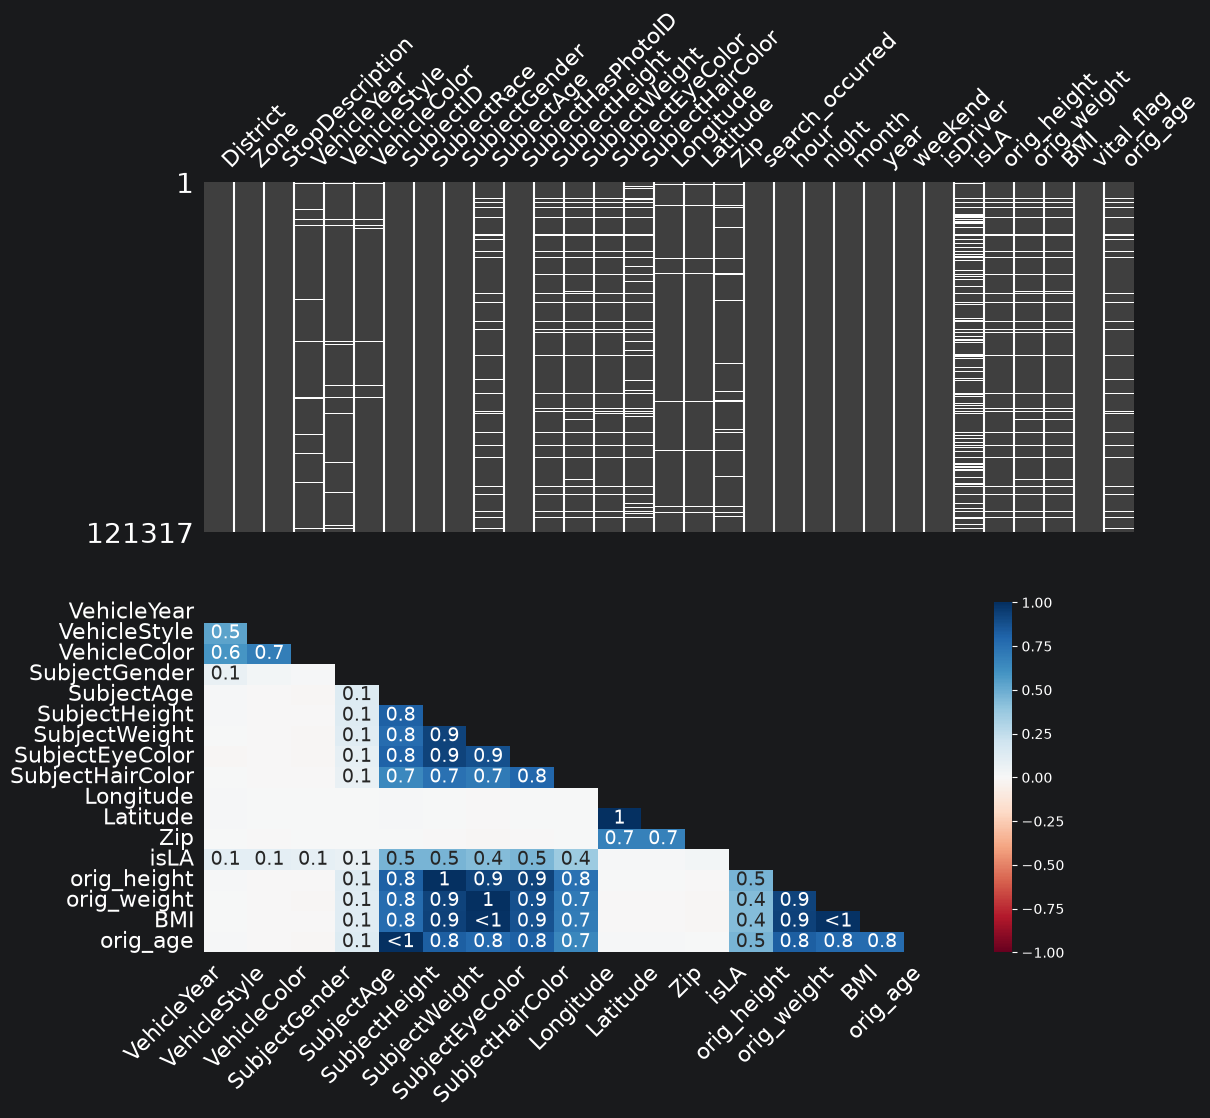

In [346]:
# Visualize missingness pattern in training data
fig, ax = plt.subplots(2, 1, figsize=(12, 10))
msno.matrix(train_df, ax=ax[0])
msno.heatmap(train_df, ax=ax[1])
plt.show()

In [352]:
train_df = train_df.drop(["orig_age", "vital_flag", "orig_height", "orig_weight", "BMI"], axis = 1)

In [353]:
train_df

,District,Zone,StopDescription,VehicleYear,VehicleStyle,VehicleColor,SubjectID,SubjectRace,SubjectGender,SubjectAge,...,Latitude,Zip,search_occurred,hour,night,month,year,weekend,isDriver,isLA
FieldInterviewID,,,,,,,,,,,,,,,,,,,,,
542115,3,D,SUSPECT VEHICLE,2014.0,FOUR DOOR,BLUE,621847,BLACK,0.0,22.0,...,30.005171,70122.0,1,22,1,8,2020,0,1,1.0
667644,5,K,TRAFFIC VIOLATION,2007.0,SPORTS UTILITY,BLACK,761029,BLACK,0.0,57.0,...,29.983293,70119.0,0,21,1,4,2025,0,1,1.0
617735,4,D,TRAFFIC VIOLATION,2022.0,SPORTS UTILITY,GRAY,705410,UNKNOWN,0.0,25.0,...,29.920947,70114.0,0,4,1,7,2023,1,1,0.0
482625,3,U,TRAFFIC VIOLATION,2005.0,TWO DOOR,WHITE,549929,BLACK,1.0,19.0,...,30.003859,70126.0,0,20,1,11,2018,0,0,NaN
452319,6,M,TRAFFIC VIOLATION,2011.0,NaN,BLUE,514827,BLACK,0.0,29.0,...,29.953352,70125.0,0,0,1,5,2018,0,1,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
524702,7,C,SUSPECT VEHICLE,2009.0,SPORTS UTILITY,SILVER,600525,BLACK,1.0,32.0,...,30.013759,70126.0,0,20,1,10,2019,0,1,0.0
677968,3,E,TRAFFIC VIOLATION,2015.0,SPORTS UTILITY,TAN,772166,BLACK,1.0,45.0,...,30.005085,70124.0,0,20,1,7,2025,1,1,1.0
643239,6,H,SUSPECT VEHICLE,2007.0,SPORTS UTILITY,WHITE,732907,BLACK,1.0,42.0,...,29.942966,70113.0,1,15,0,6,2024,0,1,1.0


In [355]:
# Ordinal encoding to run MICE imputation
encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan)

# Defining categorical columns to be imputed
cat_cols = ["VehicleStyle", "VehicleColor", "SubjectRace", "SubjectEyeColor", "SubjectHairColor", "Zip", "Zone", "StopDescription"]
# Defining discrete columns to be imputed
dis_cols = ["SubjectGender", "SubjectAge", "SubjectHeight", "SubjectWeight", "isLA"]
# Drop outcome variable
train_df_enc = train_df.copy()
search_col = train_df_enc["search_occurred"]
train_df_enc = train_df_enc.drop(["search_occurred"], axis=1)

# Ordinal encoding categorical columns, converts ZIP code to string as well
train_df_enc[cat_cols] = encoder.fit_transform(train_df[cat_cols].astype(str))

# Ensure that nan are mapped to na instead of being treated as an actual category
train_df_enc[cat_cols] = train_df_enc[cat_cols].mask(train_df_enc[cat_cols].isna())

# Random forest imputation
imputer = IterativeImputer(estimator=RandomForestRegressor(n_estimators=10, random_state=10), max_iter=10, random_state=10)

train_df_imputed = pd.DataFrame(imputer.fit_transform(train_df_enc), columns = train_df_enc.columns)

In [356]:
# Round imputations into discrete values
train_df_imputed[cat_cols] = train_df_imputed[cat_cols].round()
train_df_imputed[dis_cols] = train_df_imputed[dis_cols].round()
# Encode back to original labels
train_df_imputed_final = train_df_imputed.copy()
train_df_imputed_final[cat_cols] = encoder.inverse_transform(train_df_imputed[cat_cols])

# Return back to original index
train_df_imputed_final.index = train_df.index

# Return outcome variable, address, stopdate
train_df_imputed_final["search_occurred"] = search_col

train_df_imputed_final["BlockAddress"] = address

train_df_imputed_final["StopDate"] = date

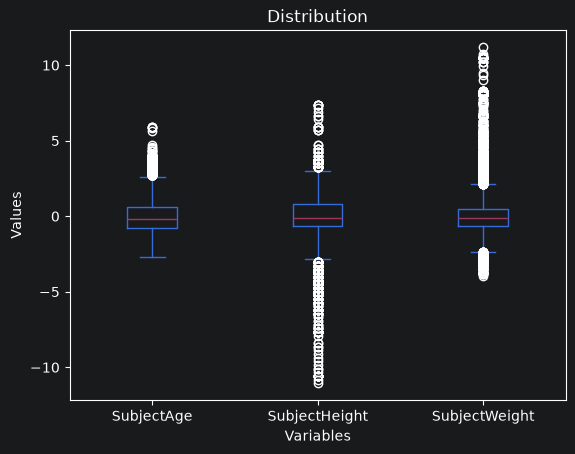

In [361]:
# Boxplots
target_df = train_df_imputed_final[["SubjectAge", "SubjectHeight", "SubjectWeight"]]

target_df = target_df.apply(zscore)

ax = target_df.plot(kind="box", title="Distribution")
plt.ylabel("Values")
plt.xlabel("Variables")
plt.show()

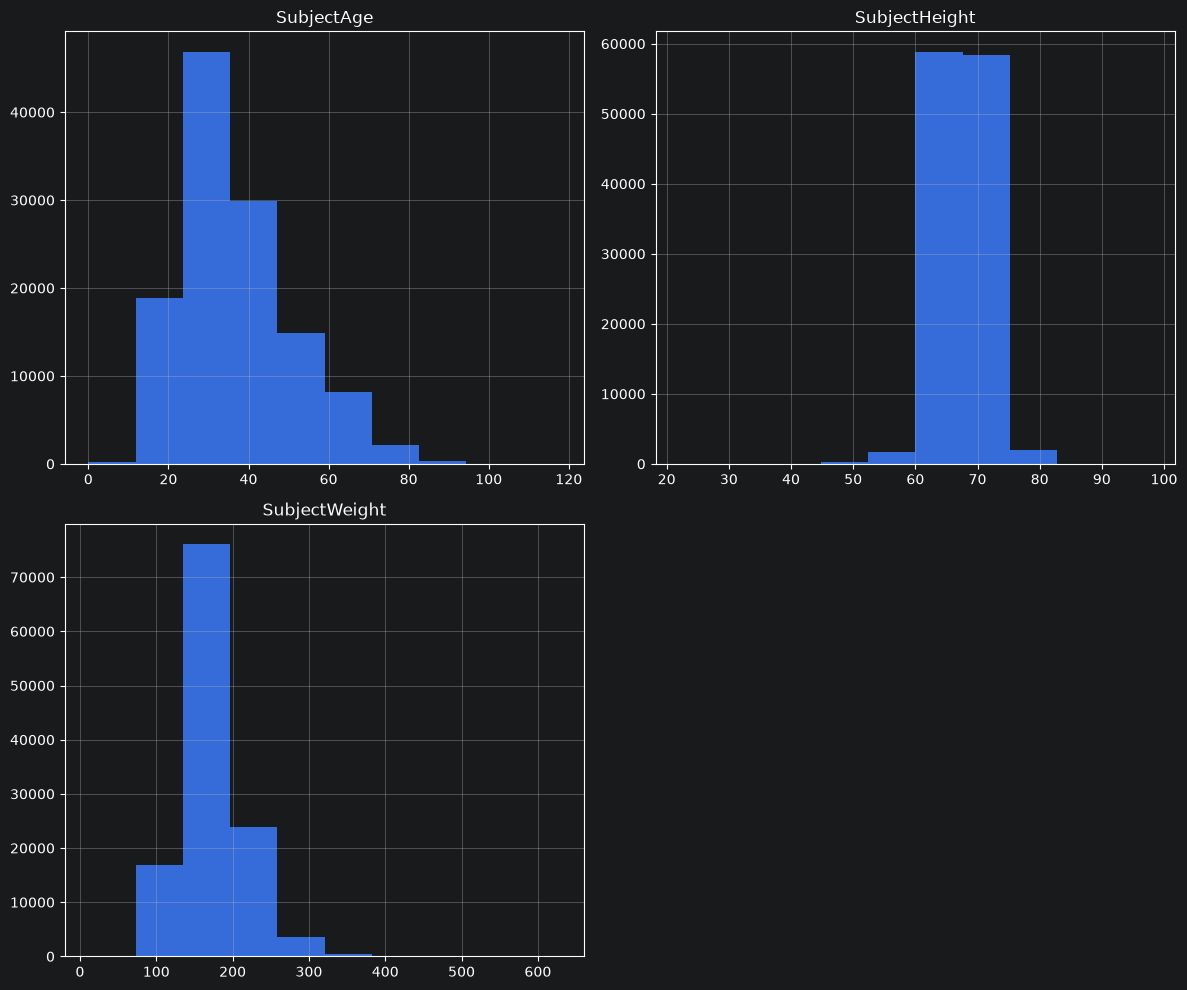

In [362]:
# Histograms
target_df = train_df_imputed_final[["SubjectAge", "SubjectHeight", "SubjectWeight"]]

target_df.hist(figsize=(12, 10))
plt.tight_layout()
plt.show()

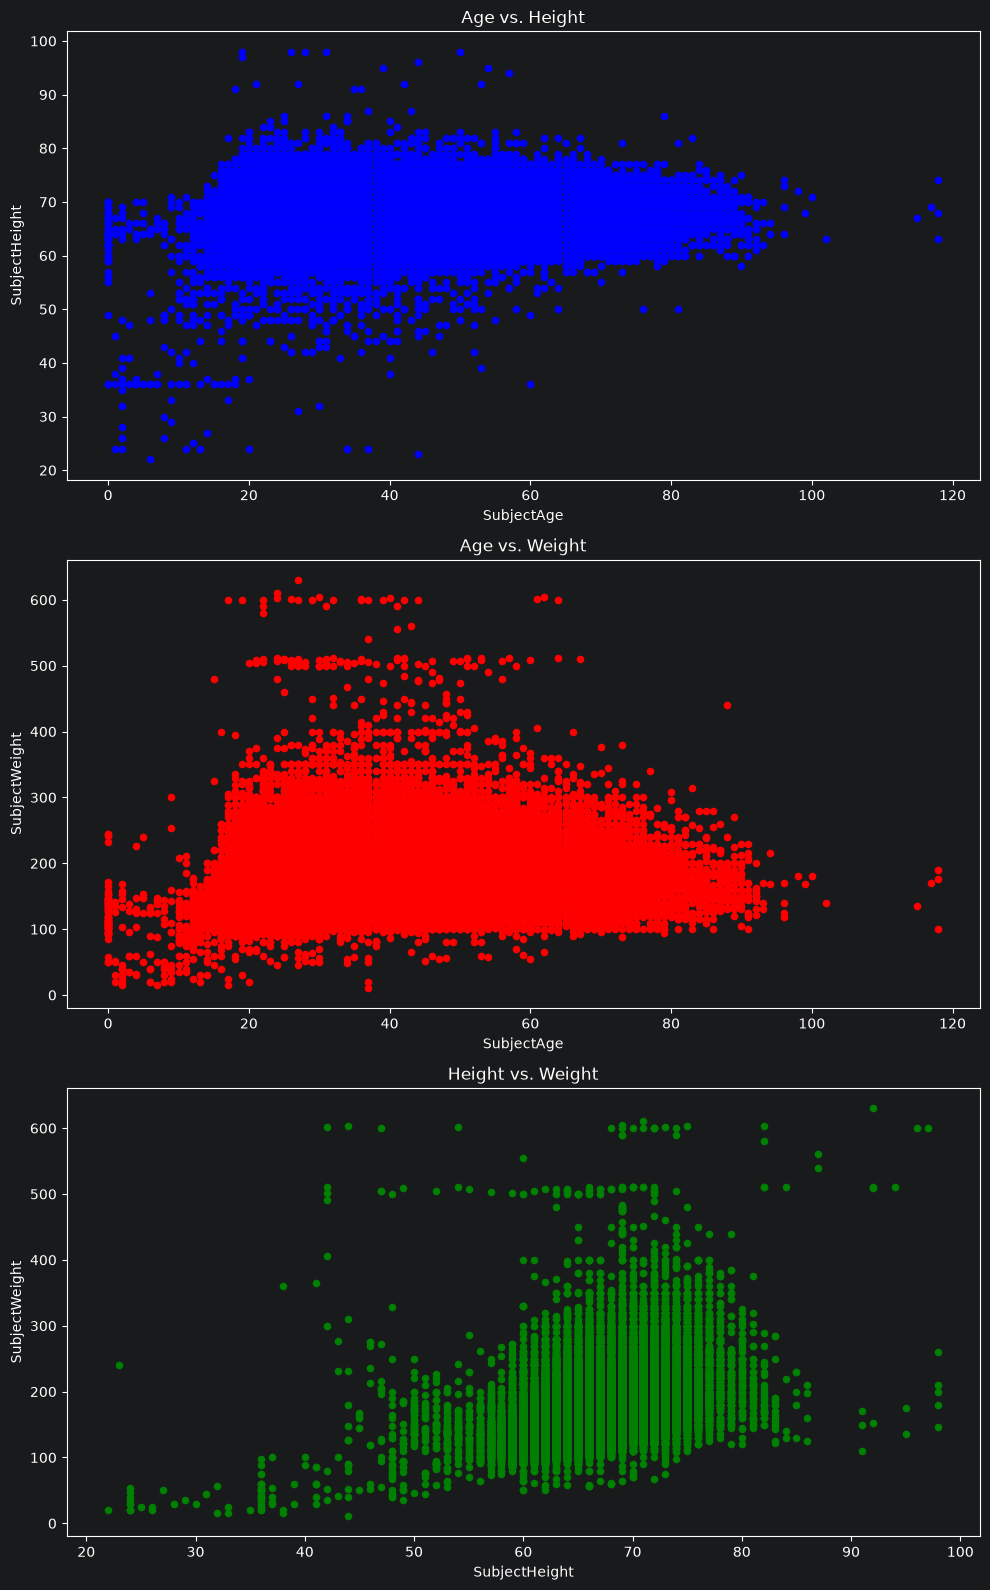

In [363]:
fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(10, 16))

train_df_imputed_final.plot.scatter(x="SubjectAge", y="SubjectHeight", ax=axes[0], color="blue", title="Age vs. Height", )
train_df_imputed_final.plot.scatter(x="SubjectAge", y="SubjectWeight", ax=axes[1], color="red", title="Age vs. Weight")
train_df_imputed_final.plot.scatter(x="SubjectHeight", y="SubjectWeight", ax=axes[2], color="green", title="Height vs. Weight")

plt.tight_layout()
plt.show()

In [364]:
train_df_imputed_final.to_csv(r"C:\Users\gelet\PycharmProjects\stop-and-search\data\cleaned_data\stop_search_train_imputed.csv", index=False)